## Introduction

Brain tumors are among the serious medical conditions that require accurate diagnosis and continuous monitoring. Magnetic Resonance Imaging (MRI) plays an important role in examining brain structures and identifying abnormal tissue regions. However, manually identifying and outlining tumor regions in MRI scans can be time-consuming and may vary depending on the medical expert.

This project focuses on Brain Tumor Segmentation using Deep Learning techniques, aiming to automatically identify and delineate tumor regions at the pixel level.

Before developing the segmentation models, an Exploratory Data Analysis (EDA) process is conducted on the LGG MRI Segmentation Dataset. This stage aims to understand the dataset structure, examine image and mask quality, analyze tumor distribution, investigate tumor area variations, and identify potential challenges that may affect model performance.

The insights obtained from this analysis provide a foundation for data preprocessing, model development, and reliable evaluation of the proposed segmentation architectures, including U-Net and SegFormer.

In [7]:
import os
import glob
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from IPython.display import display

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

DATA_ROOT = "/content/brain_tumor_data/kaggle_3m"

EDA_DIR = "/content/brain_tumor_eda_report"
FIGURES_DIR = os.path.join(EDA_DIR, "figures")

os.makedirs(FIGURES_DIR, exist_ok=True)

print("Dataset directory:", DATA_ROOT)
print("EDA output directory:", EDA_DIR)
print("Dataset directory exists:", os.path.isdir(DATA_ROOT))

Dataset directory: /content/brain_tumor_data/kaggle_3m
EDA output directory: /content/brain_tumor_eda_report
Dataset directory exists: True


In [2]:
from google.colab import files
uploaded = files.upload()

Saving kaggle.json to kaggle.json


In [9]:
records = []

for idx, (image_path, mask_path) in enumerate(paired_images):

    try:
        with Image.open(image_path) as img:
            image = np.array(img.convert("L"))

        with Image.open(mask_path) as msk:
            mask = np.array(msk.convert("L"))

        # Binary ground-truth mask
        binary_mask = mask > 0

        total_pixels = binary_mask.size
        tumor_pixels = int(binary_mask.sum())

        has_tumor = tumor_pixels > 0

        tumor_area_pct = (
            tumor_pixels / total_pixels
        ) * 100

        patient_id = os.path.basename(
            os.path.dirname(image_path)
        )

        records.append({
            "sample_id": idx,
            "patient_id": patient_id,
            "image_path": image_path,
            "mask_path": mask_path,
            "image_width": image.shape[1],
            "image_height": image.shape[0],
            "mask_width": mask.shape[1],
            "mask_height": mask.shape[0],
            "has_tumor": has_tumor,
            "tumor_pixels": tumor_pixels,
            "tumor_area_pct": tumor_area_pct,
            "image_mean_intensity": float(image.mean()),
            "image_std_intensity": float(image.std())
        })

    except Exception as e:
        print(f"Error processing {image_path}: {e}")

df = pd.DataFrame(records)

print("EDA DataFrame created successfully!")
print("Shape:", df.shape)

display(df.head())

EDA DataFrame created successfully!
Shape: (3929, 13)


,sample_id,patient_id,image_path,mask_path,image_width,image_height,mask_width,mask_height,has_tumor,tumor_pixels,tumor_area_pct,image_mean_intensity,image_std_intensity
0,0,TCGA_CS_4941_19960909,/content/brain_tumor_data/kaggle_3m/TCGA_CS_49...,/content/brain_tumor_data/kaggle_3m/TCGA_CS_49...,256,256,256,256,False,0,0.000000,26.629684,30.693888
1,1,TCGA_CS_4941_19960909,/content/brain_tumor_data/kaggle_3m/TCGA_CS_49...,/content/brain_tumor_data/kaggle_3m/TCGA_CS_49...,256,256,256,256,False,0,0.000000,42.082306,37.914901
2,2,TCGA_CS_4941_19960909,/content/brain_tumor_data/kaggle_3m/TCGA_CS_49...,/content/brain_tumor_data/kaggle_3m/TCGA_CS_49...,256,256,256,256,True,1426,2.175903,42.302826,37.234287
3,3,TCGA_CS_4941_19960909,/content/brain_tumor_data/kaggle_3m/TCGA_CS_49...,/content/brain_tumor_data/kaggle_3m/TCGA_CS_49...,256,256,256,256,True,2646,4.037476,42.271408,36.217656
4,4,TCGA_CS_4941_19960909,/content/brain_tumor_data/kaggle_3m/TCGA_CS_49...,/content/brain_tumor_data/kaggle_3m/TCGA_CS_49...,256,256,256,256,True,2765,4.219055,41.474808,35.952099


In [10]:
total_images = len(df)

positive_images = int(df["has_tumor"].sum())
empty_images = total_images - positive_images

total_patients = df["patient_id"].nunique()

overview = pd.DataFrame({
    "Metric": [
        "Total MRI images",
        "Total matched masks",
        "Matched pairs",
        "Unmatched MRI images",
        "Number of patients",
        "Images with tumor",
        "Images with empty masks",
        "Tumor images percentage",
        "Empty masks percentage"
    ],
    "Value": [
        len(image_paths),
        len(mask_paths),
        len(paired_images),
        len(unmatched_images),
        total_patients,
        positive_images,
        empty_images,
        round(positive_images / total_images * 100, 2),
        round(empty_images / total_images * 100, 2)
    ]
})

print("=== DATASET OVERVIEW ===")
display(overview)

overview.to_csv(
    os.path.join(EDA_DIR, "dataset_overview.csv"),
    index=False
)

=== DATASET OVERVIEW ===


,Metric,Value
0,Total MRI images,3929.00
1,Total matched masks,3929.00
2,Matched pairs,3929.00
3,Unmatched MRI images,0.00
4,Number of patients,110.00
5,Images with tumor,1373.00
6,Images with empty masks,2556.00
7,Tumor images percentage,34.95
8,Empty masks percentage,65.05


In [11]:
dimension_mismatches = df[
    (df["image_width"] != df["mask_width"]) |
    (df["image_height"] != df["mask_height"])
]

print("=== DATA QUALITY AUDIT ===")
print("Total samples:", len(df))
print("Dimension mismatches:", len(dimension_mismatches))
print("Unmatched images:", len(unmatched_images))
print("Duplicate image paths:", df["image_path"].duplicated().sum())
print("Duplicate mask paths:", df["mask_path"].duplicated().sum())

print("\nImage dimensions:")
display(
    df.groupby(
        ["image_width", "image_height"]
    ).size().reset_index(name="count")
)

# Inspect unique mask values in representative samples
mask_value_samples = []

for _, row in df.head(20).iterrows():

    mask = np.array(
        Image.open(row["mask_path"]).convert("L")
    )

    mask_value_samples.extend(
        np.unique(mask).tolist()
    )

print(
    "\nUnique mask values in first 20 samples:",
    sorted(set(mask_value_samples))
)

=== DATA QUALITY AUDIT ===
Total samples: 3929
Dimension mismatches: 0
Unmatched images: 0
Duplicate image paths: 0
Duplicate mask paths: 0

Image dimensions:


,image_width,image_height,count
0,256,256,3929



Unique mask values in first 20 samples: [0, 255]


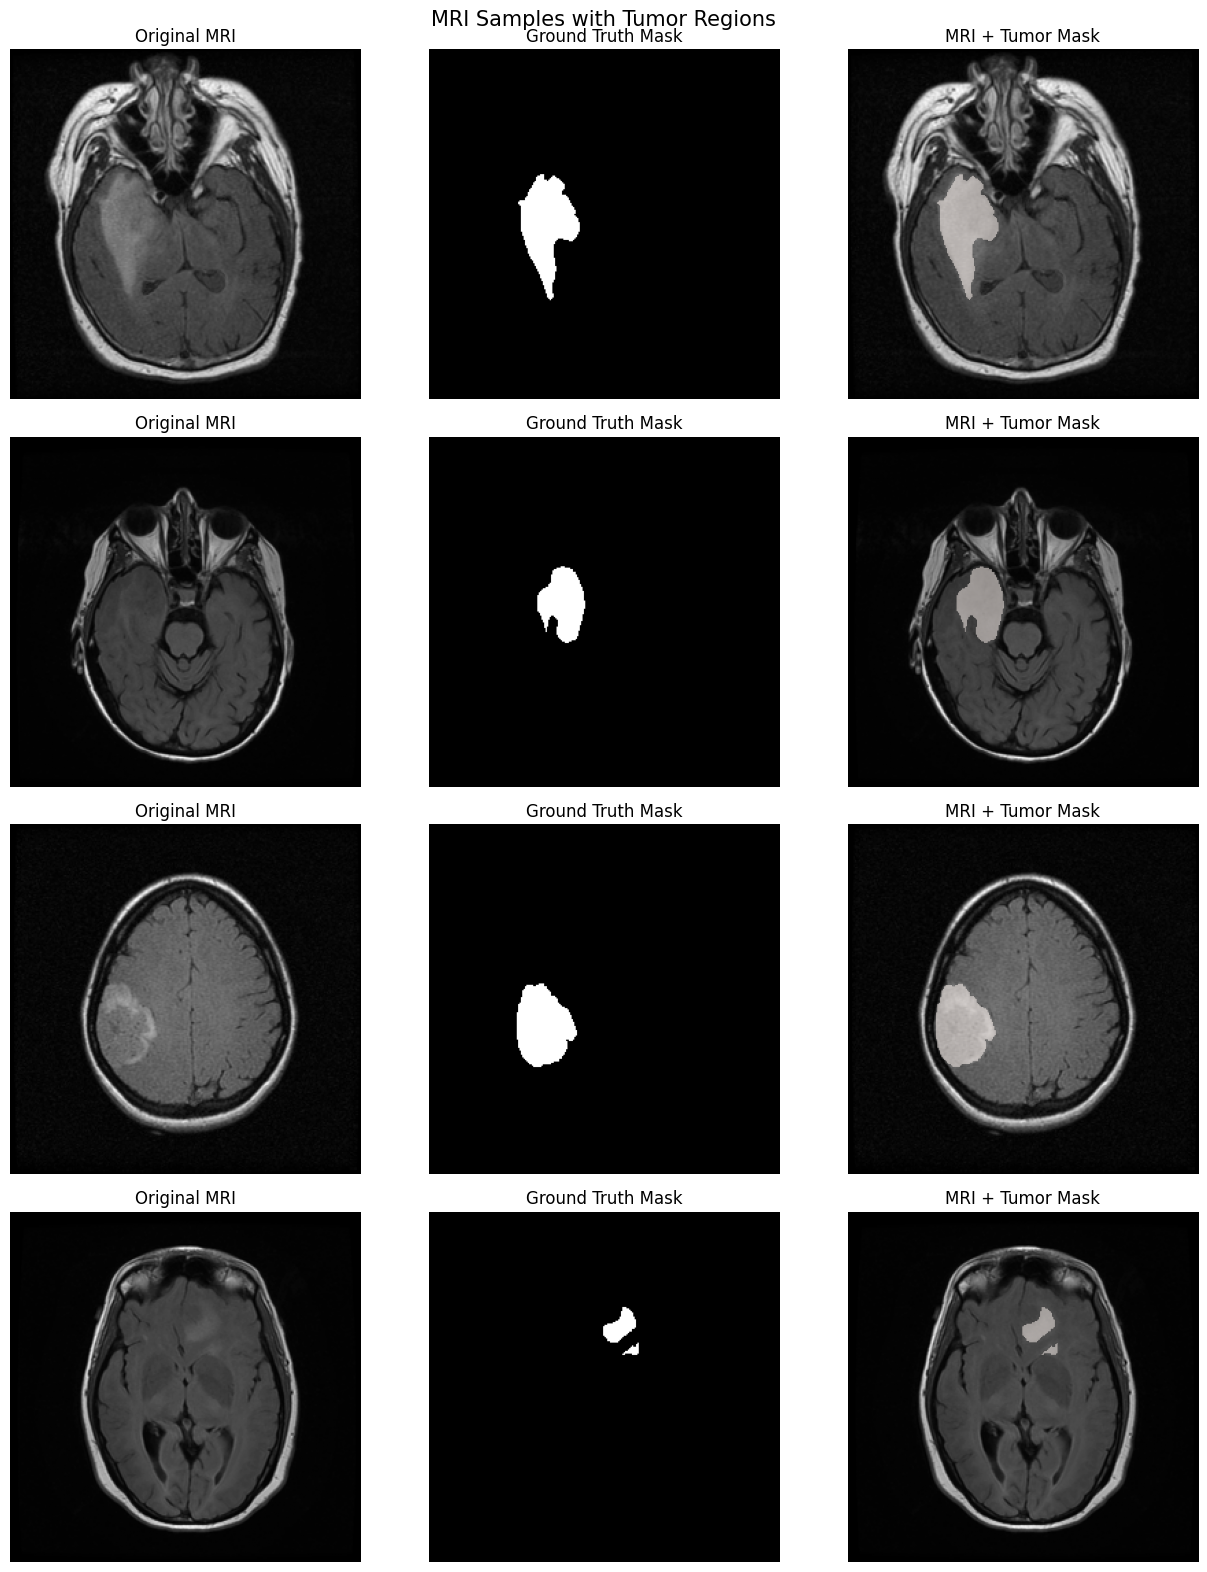

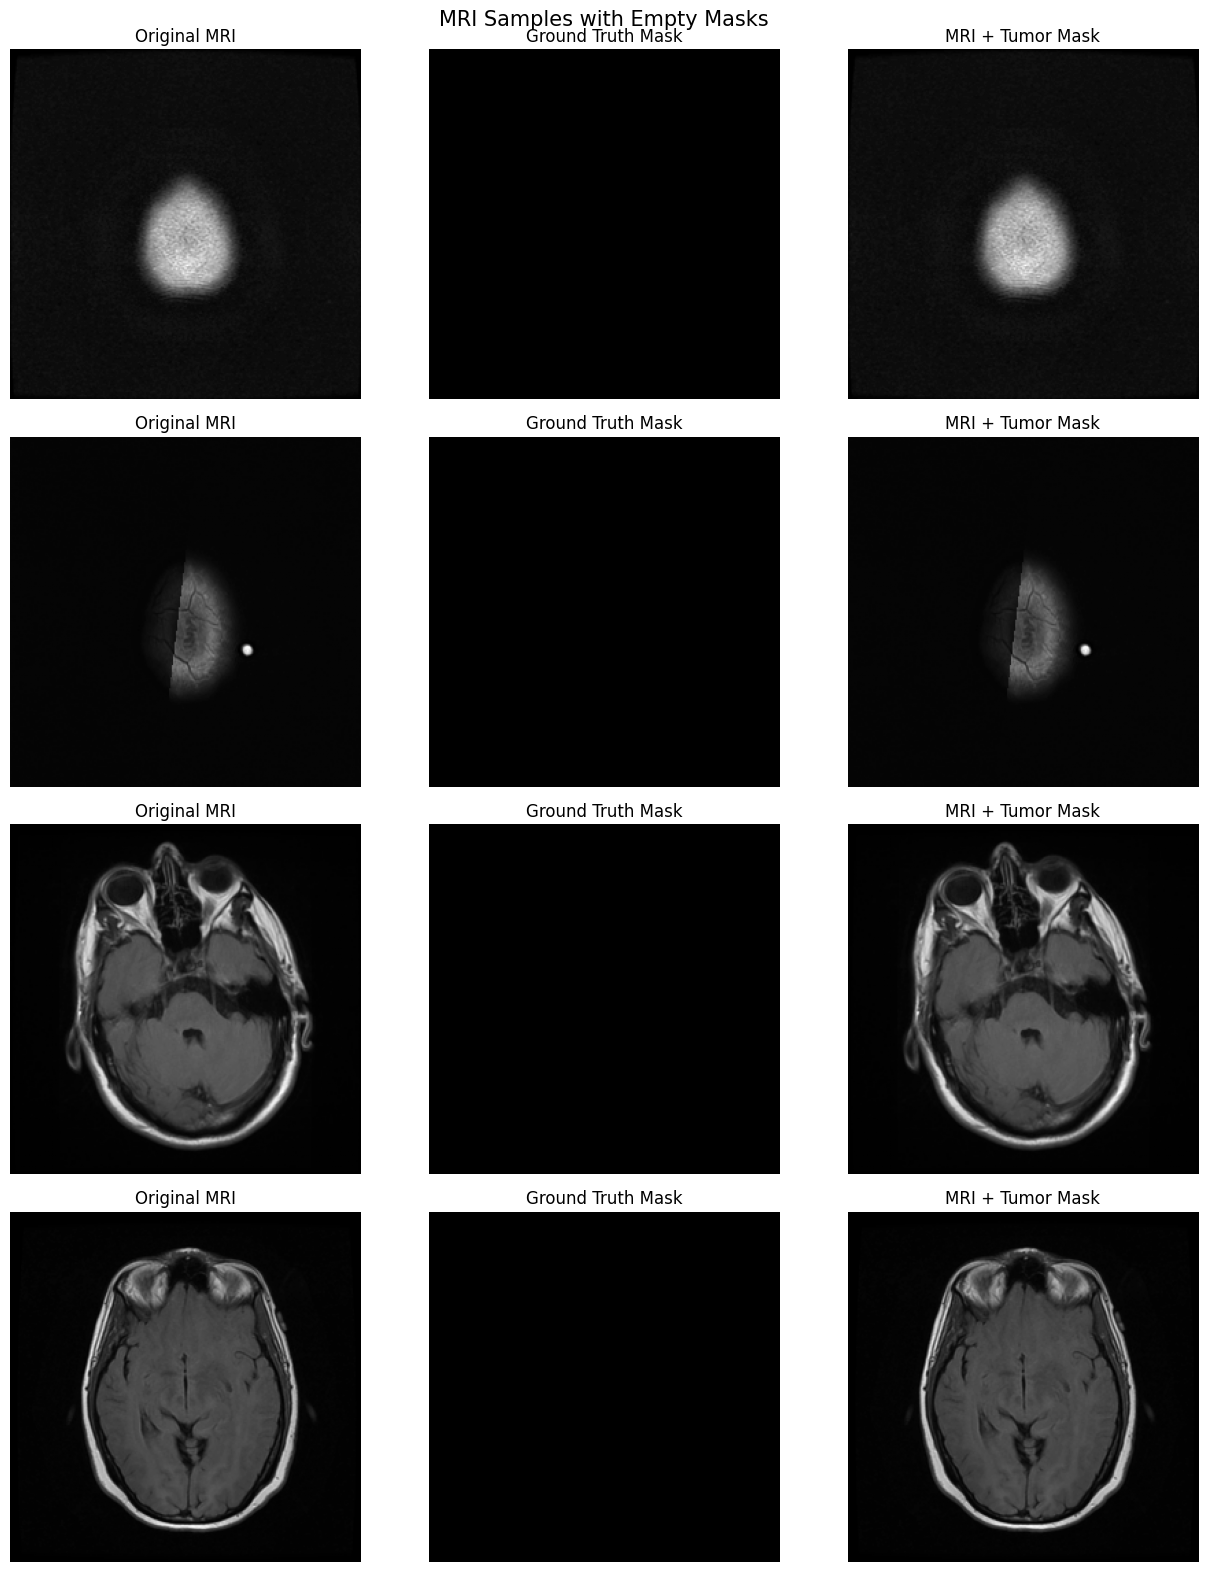

In [12]:
def display_samples(dataframe, title, n=4, positive=True):

    subset = dataframe[
        dataframe["has_tumor"] == positive
    ]

    if len(subset) == 0:
        print("No samples available:", title)
        return

    n = min(n, len(subset))

    samples = subset.sample(
        n=n,
        random_state=SEED
    )

    fig, axes = plt.subplots(
        n, 3,
        figsize=(13, 4 * n)
    )

    if n == 1:
        axes = np.expand_dims(axes, axis=0)

    for i, (_, row) in enumerate(samples.iterrows()):

        image = np.array(
            Image.open(row["image_path"]).convert("L")
        )

        mask = np.array(
            Image.open(row["mask_path"]).convert("L")
        ) > 0

        axes[i, 0].imshow(image, cmap="gray")
        axes[i, 0].set_title("Original MRI")

        axes[i, 1].imshow(mask, cmap="gray")
        axes[i, 1].set_title("Ground Truth Mask")

        axes[i, 2].imshow(image, cmap="gray")
        axes[i, 2].imshow(
            np.ma.masked_where(~mask, mask),
            cmap="Reds",
            alpha=0.5
        )
        axes[i, 2].set_title("MRI + Tumor Mask")

        for ax in axes[i]:
            ax.axis("off")

    plt.suptitle(title, fontsize=15)
    plt.tight_layout()

    filename = (
        "positive_samples.png"
        if positive else "empty_mask_samples.png"
    )

    plt.savefig(
        os.path.join(FIGURES_DIR, filename),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


display_samples(
    df,
    "MRI Samples with Tumor Regions",
    n=4,
    positive=True
)

display_samples(
    df,
    "MRI Samples with Empty Masks",
    n=4,
    positive=False
)

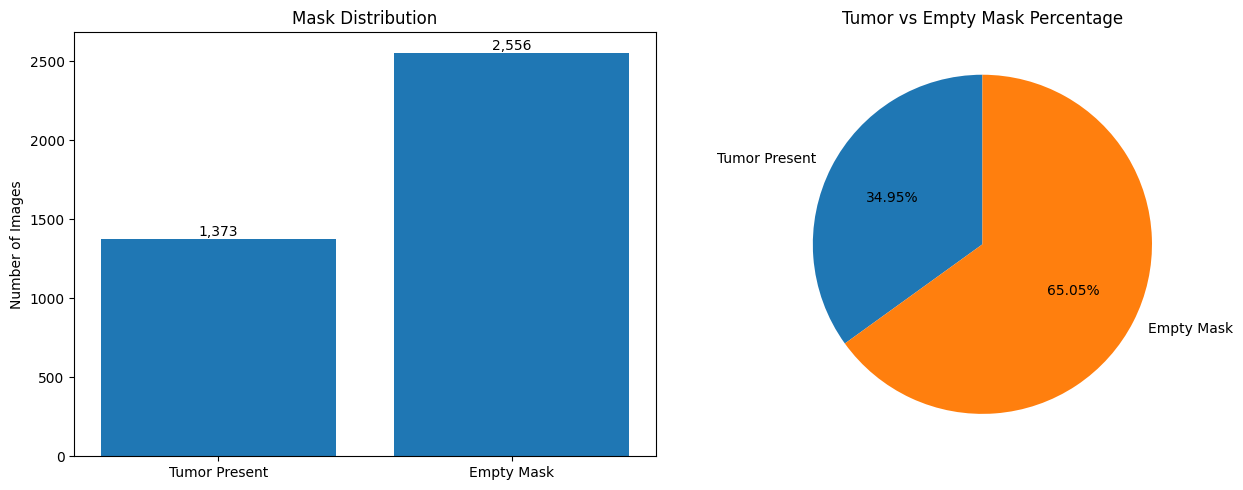

Positive images: 1373
Empty images: 2556


In [13]:
counts = df["has_tumor"].value_counts().reindex(
    [True, False],
    fill_value=0
)

labels = ["Tumor Present", "Empty Mask"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(labels, counts.values)
axes[0].set_title("Mask Distribution")
axes[0].set_ylabel("Number of Images")

for i, value in enumerate(counts.values):
    axes[0].text(
        i, value,
        f"{value:,}",
        ha="center",
        va="bottom"
    )

axes[1].pie(
    counts.values,
    labels=labels,
    autopct="%1.2f%%",
    startangle=90
)
axes[1].set_title("Tumor vs Empty Mask Percentage")

plt.tight_layout()

plt.savefig(
    os.path.join(FIGURES_DIR, "mask_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Positive images:", positive_images)
print("Empty images:", empty_images)

=== TUMOR AREA STATISTICS (%) ===


,tumor_area_pct
count,1373.000000
mean,2.947129
std,2.334002
min,0.010681
25%,1.121521
50%,2.333069
75%,4.219055
max,12.098694


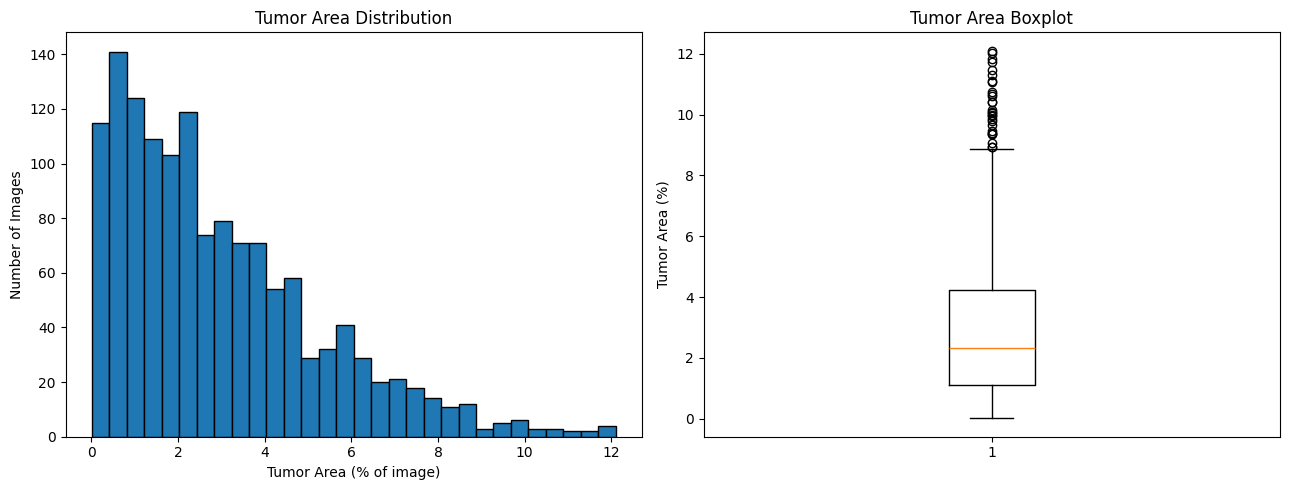

In [15]:
positive_areas = df.loc[
    df["has_tumor"],
    "tumor_area_pct"
]

print("=== TUMOR AREA STATISTICS (%) ===")
display(positive_areas.describe())

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].hist(
    positive_areas,
    bins=30,
    edgecolor="black"
)
axes[0].set_title("Tumor Area Distribution")
axes[0].set_xlabel("Tumor Area (% of image)")
axes[0].set_ylabel("Number of Images")

axes[1].boxplot(positive_areas)
axes[1].set_title("Tumor Area Boxplot")
axes[1].set_ylabel("Tumor Area (%)")

plt.tight_layout()

plt.savefig(
    os.path.join(FIGURES_DIR, "tumor_area_analysis.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

positive_areas.describe().to_csv(
    os.path.join(EDA_DIR, "tumor_area_statistics.csv")
)

Number of patients: 110

Patient distribution:


,patient_id,total_images,positive_images,total_tumor_pixels,empty_images
0,TCGA_CS_4941_19960909,23,8,14379,15
1,TCGA_CS_4942_19970222,20,6,7112,14
2,TCGA_CS_4943_20000902,20,8,14535,12
3,TCGA_CS_4944_20010208,20,9,28110,11
4,TCGA_CS_5393_19990606,20,8,29990,12
5,TCGA_CS_5395_19981004,20,3,2356,17
6,TCGA_CS_5396_20010302,24,11,32018,13
7,TCGA_CS_5397_20010315,22,6,5078,16
8,TCGA_CS_6186_20000601,25,6,8841,19
9,TCGA_CS_6188_20010812,24,4,2068,20


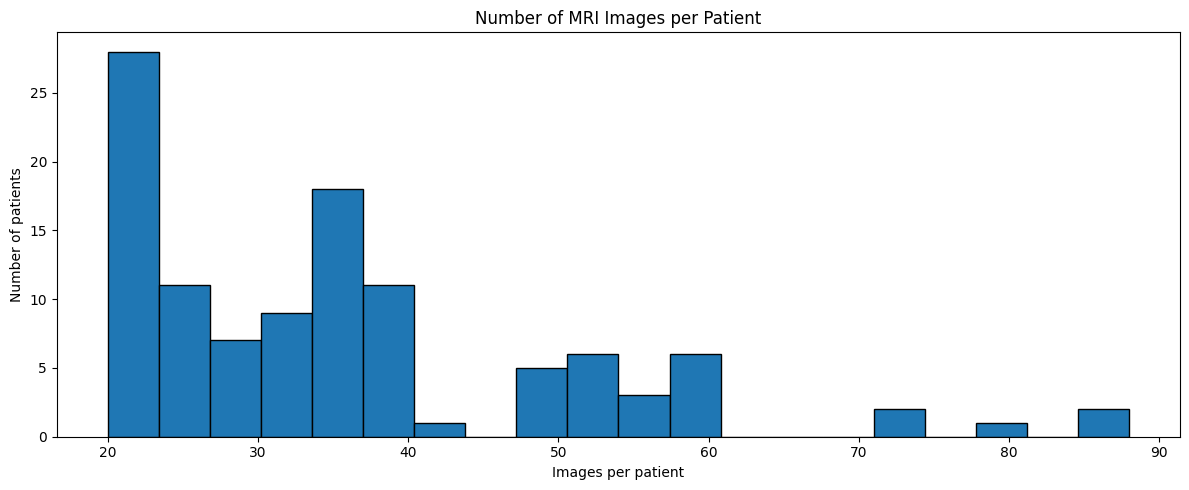

In [18]:
patient_distribution = (
    df.groupby("patient_id")
    .agg(
        total_images=("sample_id", "count"),
        positive_images=("has_tumor", "sum"),
        total_tumor_pixels=("tumor_pixels", "sum")
    )
    .reset_index()
)

patient_distribution["empty_images"] = (
    patient_distribution["total_images"]
    - patient_distribution["positive_images"]
)

print("Number of patients:", len(patient_distribution))
print("\nPatient distribution:")
display(patient_distribution.head(10))

plt.figure(figsize=(12, 5))

plt.hist(
    patient_distribution["total_images"],
    bins=20,
    edgecolor="black"
)

plt.title("Number of MRI Images per Patient")
plt.xlabel("Images per patient")
plt.ylabel("Number of patients")

plt.tight_layout()

plt.savefig(
    os.path.join(FIGURES_DIR, "patient_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

patient_distribution.to_csv(
    os.path.join(EDA_DIR, "patient_distribution.csv"),
    index=False
)

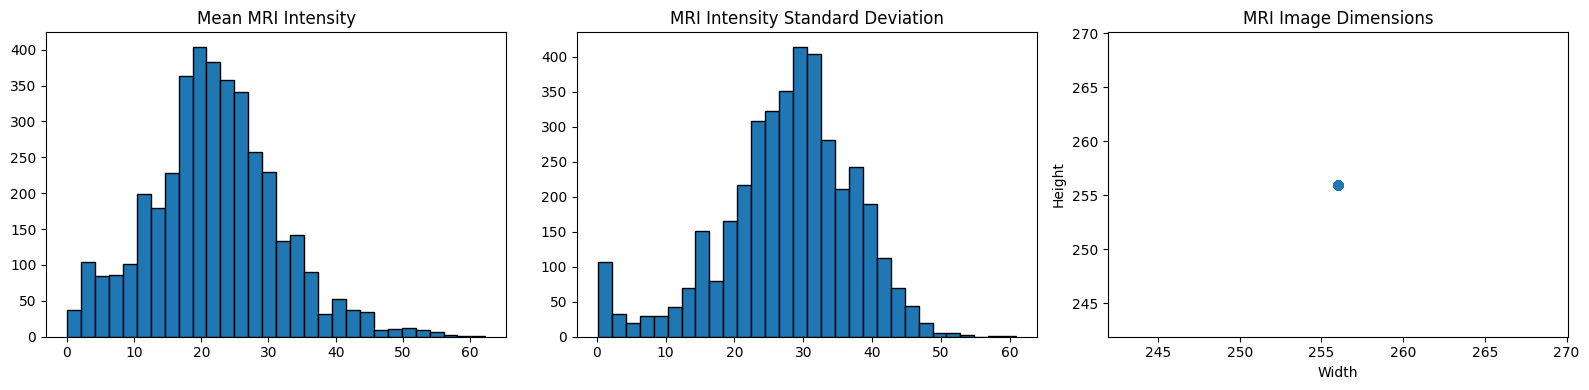

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(
    df["image_mean_intensity"],
    bins=30,
    edgecolor="black"
)
axes[0].set_title("Mean MRI Intensity")

axes[1].hist(
    df["image_std_intensity"],
    bins=30,
    edgecolor="black"
)
axes[1].set_title("MRI Intensity Standard Deviation")

axes[2].scatter(
    df["image_width"],
    df["image_height"],
    alpha=0.5
)
axes[2].set_title("MRI Image Dimensions")
axes[2].set_xlabel("Width")
axes[2].set_ylabel("Height")

plt.tight_layout()

plt.savefig(
    os.path.join(FIGURES_DIR, "image_properties.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [20]:
print("=== DATASET CHALLENGES ===")

imbalance_ratio = (
    empty_images / positive_images
    if positive_images > 0 else np.inf
)

print(
    f"Empty-to-positive image ratio: "
    f"{imbalance_ratio:.2f}:1"
)

print(
    f"Positive images: "
    f"{positive_images} "
    f"({positive_images / total_images * 100:.2f}%)"
)

print(
    f"Empty masks: "
    f"{empty_images} "
    f"({empty_images / total_images * 100:.2f}%)"
)

print(
    "Patients:", total_patients
)

print(
    "Dimension mismatches:",
    len(dimension_mismatches)
)

print(
    "Unmatched images:",
    len(unmatched_images)
)

=== DATASET CHALLENGES ===
Empty-to-positive image ratio: 1.86:1
Positive images: 1373 (34.95%)
Empty masks: 2556 (65.05%)
Patients: 110
Dimension mismatches: 0
Unmatched images: 0


In [21]:
# Save the complete sample-level analysis
df.to_csv(
    os.path.join(EDA_DIR, "complete_eda_analysis.csv"),
    index=False
)

# Save dataset quality information
quality_summary = pd.DataFrame({
    "Metric": [
        "Total MRI images",
        "Matched pairs",
        "Unmatched images",
        "Dimension mismatches",
        "Number of patients"
    ],
    "Value": [
        len(image_paths),
        len(paired_images),
        len(unmatched_images),
        len(dimension_mismatches),
        total_patients
    ]
})

quality_summary.to_csv(
    os.path.join(EDA_DIR, "data_quality_audit.csv"),
    index=False
)

print("EDA report files generated successfully!")

print("\nFiles:")
for root, dirs, files in os.walk(EDA_DIR):
    for filename in sorted(files):
        print(os.path.join(root, filename))

EDA report files generated successfully!

Files:
/content/brain_tumor_eda_report/complete_eda_analysis.csv
/content/brain_tumor_eda_report/data_quality_audit.csv
/content/brain_tumor_eda_report/dataset_overview.csv
/content/brain_tumor_eda_report/patient_distribution.csv
/content/brain_tumor_eda_report/tumor_area_statistics.csv
/content/brain_tumor_eda_report/figures/empty_mask_samples.png
/content/brain_tumor_eda_report/figures/image_properties.png
/content/brain_tumor_eda_report/figures/mask_distribution.png
/content/brain_tumor_eda_report/figures/patient_distribution.png
/content/brain_tumor_eda_report/figures/positive_samples.png
/content/brain_tumor_eda_report/figures/tumor_area_analysis.png


In [5]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

DATA_ROOT = "/content/brain_tumor_data/kaggle_3m"

# Find MRI images and exclude masks
image_paths = glob.glob(
    os.path.join(DATA_ROOT, "**", "*.tif"),
    recursive=True
)

image_paths = [
    p for p in image_paths
    if not p.lower().endswith("_mask.tif")
]

print("MRI images found:", len(image_paths))

# Find images that have matching masks
paired_images = []

for image_path in image_paths:
    mask_path = image_path[:-4] + "_mask.tif"

    if os.path.exists(mask_path):
        paired_images.append((image_path, mask_path))

print("Images with matching masks:", len(paired_images))

if paired_images:
    print("\nSample image:", paired_images[0][0])
    print("Sample mask:", paired_images[0][1])
else:
    print("No matching pairs found. Check the dataset folder.")

MRI images found: 3929
Images with matching masks: 3929

Sample image: /content/brain_tumor_data/kaggle_3m/TCGA_FG_8189_20030516/TCGA_FG_8189_20030516_54.tif
Sample mask: /content/brain_tumor_data/kaggle_3m/TCGA_FG_8189_20030516/TCGA_FG_8189_20030516_54_mask.tif


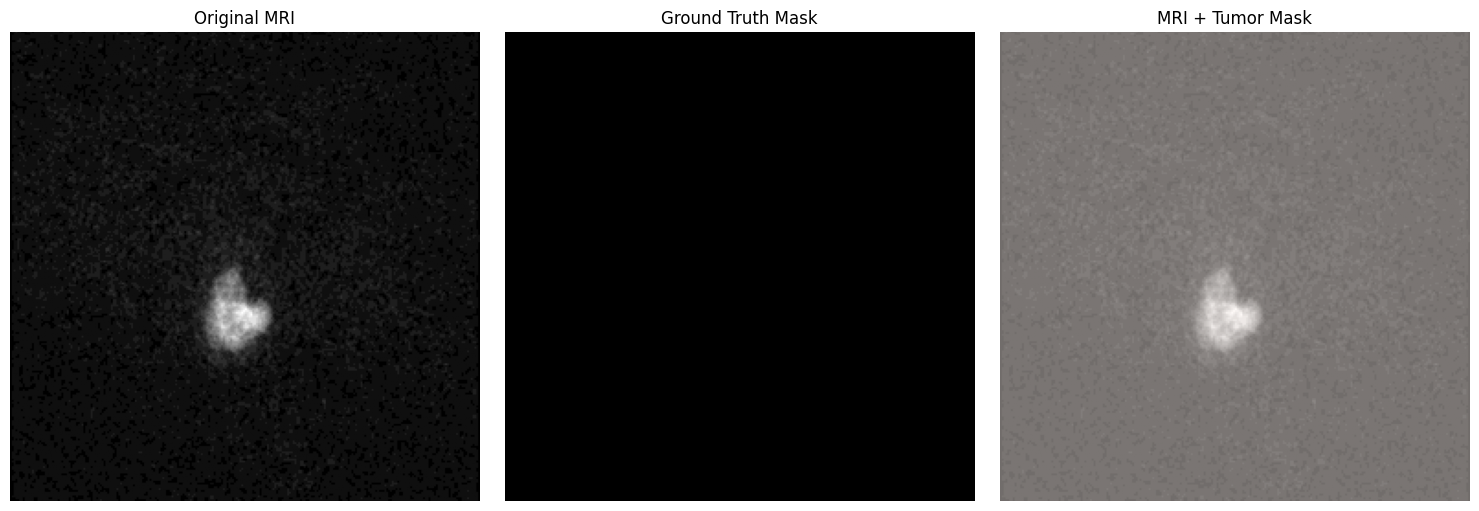

MRI shape: (256, 256)
Mask shape: (256, 256)
Tumor pixels: 0


In [6]:
# Display a sample MRI and its corresponding mask
if paired_images:
    image_path, mask_path = paired_images[0]

    mri = np.array(Image.open(image_path).convert("L"))
    mask = np.array(Image.open(mask_path).convert("L"))

    # Convert mask to binary
    mask_binary = mask > 0

    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(mri, cmap="gray")
    plt.title("Original MRI")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(mask_binary, cmap="gray")
    plt.title("Ground Truth Mask")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(mri, cmap="gray")
    plt.imshow(mask_binary, cmap="Reds", alpha=0.45)
    plt.title("MRI + Tumor Mask")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    print("MRI shape:", mri.shape)
    print("Mask shape:", mask.shape)
    print("Tumor pixels:", int(mask_binary.sum()))
else:
    print("Run Step 1 and check the matching pairs count.")

In [22]:
print("=" * 60)
print("FINAL EDA CONCLUSIONS")
print("=" * 60)

print(f"""
The dataset contains {total_images:,} MRI images
and {len(paired_images):,} matched segmentation masks.

The dataset includes {total_patients} patients.

{positive_images:,} images contain tumor regions
({positive_images / total_images * 100:.2f}%).

{empty_images:,} images have empty masks
({empty_images / total_images * 100:.2f}%).

The mean tumor area is
{positive_areas.mean():.4f}% of the image.

The dataset presents a class imbalance challenge,
because empty masks are more frequent than positive masks.

Patient-level splitting is important to reduce
data leakage between training, validation, and testing.

The EDA stage provides the foundation for
the subsequent model development and evaluation.
""")

print("EDA completed.")
print("Report directory:", EDA_DIR)

FINAL EDA CONCLUSIONS

The dataset contains 3,929 MRI images
and 3,929 matched segmentation masks.

The dataset includes 110 patients.

1,373 images contain tumor regions
(34.95%).

2,556 images have empty masks
(65.05%).

The mean tumor area is
2.9471% of the image.

The dataset presents a class imbalance challenge,
because empty masks are more frequent than positive masks.

Patient-level splitting is important to reduce
data leakage between training, validation, and testing.

The EDA stage provides the foundation for
the subsequent model development and evaluation.

EDA completed.
Report directory: /content/brain_tumor_eda_report


## Conclusion

The Exploratory Data Analysis provided a comprehensive understanding of the LGG MRI Segmentation Dataset and its main characteristics.

The analysis examined MRI image and mask matching, dataset quality, image dimensions, tumor presence distribution, tumor area statistics, and patient-level distribution. The visualizations also provided useful insights into the differences between tumor-positive images and images with empty masks.

One of the important challenges identified during the analysis is the imbalance between tumor-positive and empty-mask samples. Variations in tumor size, shape, and image intensity also represent important factors that should be considered during model development.

Overall, the EDA stage established a reliable foundation for the subsequent deep learning experiments. The findings will guide the preprocessing strategy and help interpret the performance of U-Net and SegFormer models using Dice Score, Intersection over Union (IoU), and other relevant evaluation metrics.